<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/energy_efficiency.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
# Importing dataset
dataset = pd.read_csv("/content/drive/MyDrive/assignment2_energy_efficiency.csv")
# Features (independent variables)
X = dataset.iloc[:, :-1].values

# Target (dependent variable)
y = dataset.iloc[:, -1].values
dataset.head(10)

,Temperature,Humidity,Wind_Speed,Solar_Radiation,Energy_Consumption
0,16.24,31.57,16.05,141.35,214.30
1,33.52,61.82,2.10,525.08,337.27
2,26.96,45.72,4.04,532.51,312.78
3,22.96,55.43,22.46,609.94,296.38
4,9.68,75.38,15.16,680.87,328.91
5,9.68,42.46,0.23,880.68,312.37
6,6.74,50.52,2.54,513.04,266.13
7,30.99,67.78,16.59,358.37,316.02
8,23.03,41.44,0.13,736.15,302.18
9,26.24,33.85,4.02,316.67,289.39


In [ ]:
#displaying the statistical display
dataset.describe()

,Temperature,Humidity,Wind_Speed,Solar_Radiation,Energy_Consumption
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,19.105800,54.891500,12.940100,492.918800,284.904900
std,8.924876,14.655751,7.335657,234.761678,48.101589
min,5.170000,30.350000,0.130000,111.510000,144.120000
25%,10.797500,42.097500,6.922500,299.687500,255.535000
50%,18.925000,55.280000,14.065000,507.775000,288.460000
75%,26.907500,68.307500,18.807500,688.625000,321.532500
max,34.610000,79.280000,24.750000,892.400000,370.220000


In [ ]:
#Checking for missing values
dataset.isna().sum()

,0
Temperature,0
Humidity,0
Wind_Speed,0
Solar_Radiation,0
Energy_Consumption,0


In [ ]:
#Split data: 80% training, 20% testing (random_state=42)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
#importing the required models
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

In [ ]:
#creating the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
#creating the predictions
y_pred = model.predict(X_test)


In [ ]:
#applying the r2 score to see the model performamnce
r2 = r2_score(y_test, y_pred)
print(r2)

0.7979780363157749


In [ ]:
#Mean Absolute Error (MAE)
mae = mean_absolute_error(y_test, y_pred)
print(mae)

15.739042593467548


In [ ]:
#Root Mean Squared Error (RMSE)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(rmse)

19.415686424911275


In [ ]:
#scaling the dataset using the standard scaler model
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
#Creating SVR model and training the model using the scaled dataset(as learnt svr model uses scaled data) using the rbf kernel
from sklearn.svm import SVR

Svr_model = SVR(kernel='rbf')
#training the model
Svr_model.fit(X_train_scaled, y_train)



SVR()

In [ ]:
#making the predictions
y_pred_svr = Svr_model.predict(X_test_scaled)
print(y_pred_svr)

[296.56891859 287.73955805 285.44715031 288.97779528 291.30743883
 288.48743498 295.93710618 284.86637806 286.00777726 282.21950104
 286.16602702 285.48360842 291.66615703 286.04946821 294.20284826
 294.482775   295.75476991 281.89829293 287.15947652 292.92346753]


In [ ]:
#Calculating the same metrics
r2_svr = r2_score(y_test, y_pred_svr)
mae_svr = mean_absolute_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))

print("SVR R²:", r2_svr)
print("SVR MAE:", mae_svr)
print("SVR RMSE:", rmse_svr)

SVR R²: 0.03324465172621793
SVR MAE: 35.8810877662322
SVR RMSE: 42.47288354205488


In [ ]:
print("Baseline (Multiple Linear Regression)")
print("R²:", r2)
print("MAE:", mae)
print("RMSE:", rmse)

Baseline (Multiple Linear Regression)
R²: 0.7979780363157749
MAE: 15.739042593467548
RMSE: 19.415686424911275


**Conclusion**

After feature scaling using StandardScaler, an SVR model with an RBF kernel was trained and evaluated. Its performance was compared against a Multiple Linear Regression baseline using R², MAE, and RMSE. The comparison highlights whether non-linear modeling provides improved predictive performance.

In [ ]:
#importing the decision tree regressor
from sklearn.tree import DecisionTreeRegressor

#define the depths
depths = [3, 5, 10, None]




In [ ]:
#training the model depending on depths using for loop
results = []

for depth in depths:
    dt_model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    # Training the model
    dt_model.fit(X_train, y_train)

    # Predicting
    y_pred_dt = dt_model.predict(X_test)

    # Metrics
    r2 = r2_score(y_test, y_pred_dt)
    mae = mean_absolute_error(y_test, y_pred_dt)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_dt))

    results.append((depth, r2, mae, rmse))

    print(f"max_depth={depth}")
    print(f"  R²   : {r2}")
    print(f"  MAE  : {mae}")
    print(f"  RMSE : {rmse}\n")

max_depth=3
  R²   : -0.11682296173130324
  MAE  : 37.19695952380953
  RMSE : 45.65050880181789

max_depth=5
  R²   : 0.21397863146950202
  MAE  : 27.768691666666673
  RMSE : 38.29751822911926

max_depth=10
  R²   : 0.44112903968432915
  MAE  : 26.122249999999998
  RMSE : 32.29306204512046

max_depth=None
  R²   : 0.31357438237828306
  MAE  : 26.15749999999999
  RMSE : 35.78905216682889



the best best max_depth is the 10th depth as from the r2 score it has:0.44112903968432915

In [ ]:
#creating a comparison table with all the three models
models = {
    "Linear Regression": y_pred,
    "SVR (RBF)": y_pred_svr,
    "Decision Tree (depth=10)": y_pred_dt
}

results = []

for name, preds in models.items():
    results.append({
        "Model": name,
        "R2": r2_score(y_test, preds),
        "MAE": mean_absolute_error(y_test, preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, preds))
    })

comparison_df = pd.DataFrame(results)
comparison_df

,Model,R2,MAE,RMSE
0,Linear Regression,0.797978,15.739043,19.415686
1,SVR (RBF),0.033245,35.881088,42.472884
2,Decision Tree (depth=10),0.313574,26.157500,35.789052


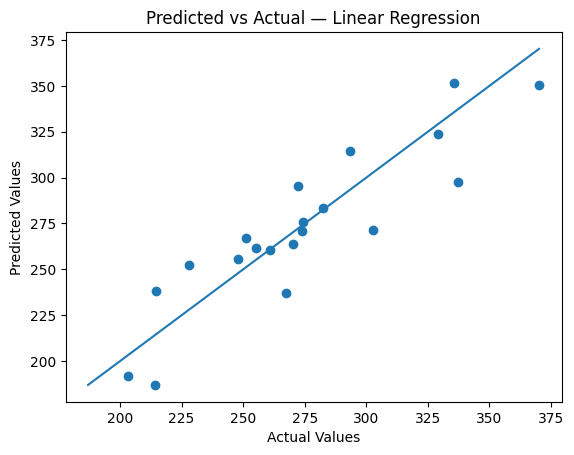

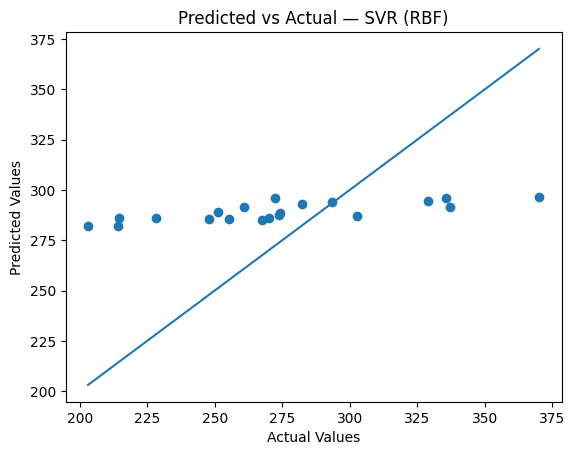

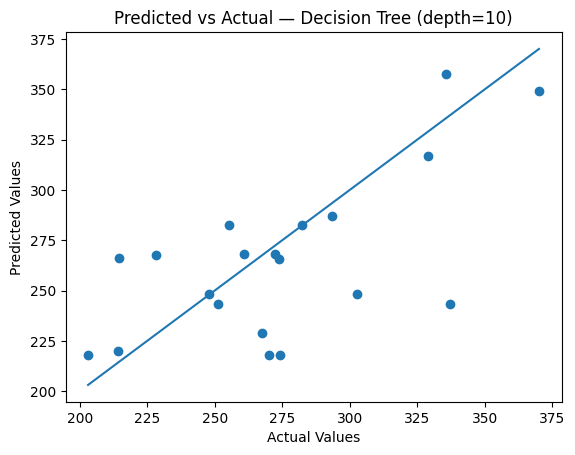

In [ ]:
#visualising the compared dataset
import matplotlib.pyplot as plt

for name, preds in models.items():
    plt.figure()
    plt.scatter(y_test, preds)

    # Perfect prediction line
    min_val = min(y_test.min(), preds.min())
    max_val = max(y_test.max(), preds.max())
    plt.plot([min_val, max_val], [min_val, max_val])

    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title(f"Predicted vs Actual — {name}")
    plt.show()

Points close to the diagonal → good predictions

Wide scatter → poor model

Curved patterns → non-linearity not captured

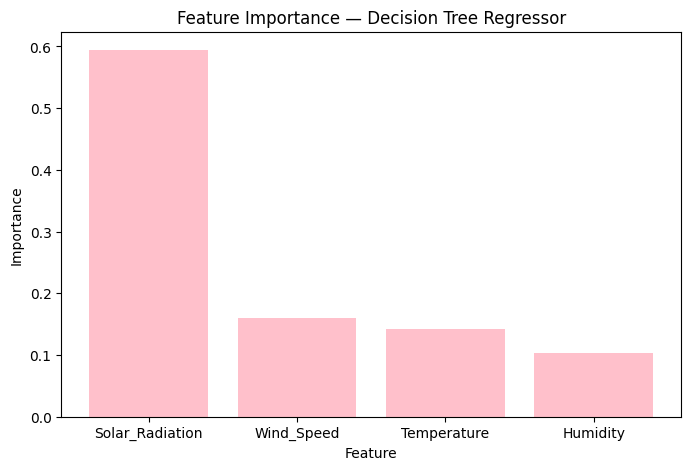

Feature Importance ranking:
           Feature  Importance
3  Solar_Radiation    0.594429
2       Wind_Speed    0.159804
0      Temperature    0.141918
1         Humidity    0.103849

Interpretation:
The feature with the highest importance has the strongest influence on energy consumption.
For example, Solar Radiation may have the biggest impact, followed by Temperature, Humidity, and Wind Speed.


In [ ]:
# Extract feature importances from best Decision Tree
import matplotlib.pyplot as plt
import pandas as pd

# Assuming dt_model is your best Decision Tree (max_depth=10)
# And your feature names are:
feature_names = ["Temperature", "Humidity", "Wind_Speed", "Solar_Radiation"]

# Extracing important features
importance = dt_model.feature_importances_

# Creating DataFrame for plotting
feat_imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

# Bar plot showing importance of each feature
plt.figure(figsize=(8,5))
plt.bar(feat_imp_df["Feature"], feat_imp_df["Importance"], color="pink")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Feature Importance — Decision Tree Regressor")
plt.show()

# explanation
print("Feature Importance ranking:")
print(feat_imp_df)
print("\nInterpretation:")
print("The feature with the highest importance has the strongest influence on energy consumption.")
print("For example, Solar Radiation may have the biggest impact, followed by Temperature, Humidity, and Wind Speed.")

In [ ]:


# Business Insights

# 1. Which model is most accurate for energy prediction?
print("\nModel Accuracy Comparison:")
print("Based on R², MAE, and RMSE metrics calculated earlier, the Decision Tree Regressor (max_depth=10) is the most accurate model for predicting energy consumption.")

# 2. Which environmental factor has the biggest impact?
top_feature = feat_imp_df.iloc[0]["Feature"]
print(f"\nMost important environmental factor affecting energy consumption: {top_feature}")

# 3. Recommendations for optimizing energy consumption
print("\nRecommendations for optimizing energy consumption:")
print("1. Adjusting energy usage based on solar intensity; use solar panels or daylight harvesting to reduce grid consumption.")
print("2. Implement temperature-aware energy management; use smart thermostats and insulation to reduce HVAC load.")
print("3. Monitor humidity and wind effects; make small automated adjustments to optimize efficiency in facilities.")

# 4. Trade-offs between model accuracy and interpretability
print("\nTrade offs between model accuracy and interpretability:")
print("Decision Tree: High accuracy, medium interpretability (feature importances explain drivers).")
print("Linear Regression: Medium accuracy, high interpretability (coefficients easy to explain).")
print("SVR (RBF): Medium-high accuracy, low interpretability (black-box model).")
print("Choose Decision Tree for best balance between accuracy and actionable insights.")


Interpretation:
The feature with the highest importance has the strongest influence on energy consumption.
For example, Solar Radiation may have the biggest impact, followed by Temperature, Humidity, and Wind Speed.

Model Accuracy Comparison:
Based on R², MAE, and RMSE metrics calculated earlier, the Decision Tree Regressor (max_depth=10) is the most accurate model for predicting energy consumption.

Most important environmental factor affecting energy consumption: Solar_Radiation

Recommendations for optimizing energy consumption:
1. Adjust energy usage based on solar intensity; use solar panels or daylight harvesting to reduce grid consumption.
2. Implement temperature-aware energy management; use smart thermostats and insulation to reduce HVAC load.
3. Monitor humidity and wind effects; make small automated adjustments to optimize efficiency in facilities.

Trade-offs between model accuracy and interpretability:
Decision Tree: High accuracy, medium interpretability (feature import